<a href="https://colab.research.google.com/github/MohammedAlhadiAsiri/telco-churn-prediction/blob/main/telco_churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.sample()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
3000,7613-LLQFO,Male,0,No,No,12,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Electronic check,84.45,1059.55,Yes


In [3]:
print(df.shape)
print('===============================================\n')
df.info()
print('===============================================\n')
df['Churn'].value_counts(normalize = True)

(7043, 21)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-nul

,proportion
Churn,
No,0.73463
Yes,0.26537


In [4]:
df.sample(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6729,2256-YLYLP,Male,0,Yes,Yes,68,Yes,No,DSL,No,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),72.95,4953.25,No
3980,8868-WOZGU,Male,0,No,No,28,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,105.70,2979.5,Yes
1965,3948-XHGNA,Male,0,No,No,24,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),49.55,1210.4,Yes
2839,5465-BUBFA,Female,0,Yes,Yes,41,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.30,772.4,No
3669,2587-EKXTS,Male,0,No,No,44,Yes,Yes,Fiber optic,Yes,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,111.50,4915.15,No
1219,2294-DMMUS,Female,0,Yes,Yes,62,Yes,Yes,DSL,No,...,No,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),70.45,4300.45,No
3303,7786-WBJYI,Female,0,No,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,No,Bank transfer (automatic),77.95,305.55,Yes
1024,7147-AYBAA,Male,0,No,No,37,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,70.35,2552.9,No
6521,1092-WPIVQ,Female,0,Yes,Yes,18,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.10,428.45,No
5584,6330-JKLPC,Male,0,Yes,No,11,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),80.50,896.9,Yes


In [5]:
df[df["TotalCharges"].str.strip() == ""][["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,
753,0,20.25,
936,0,80.85,
1082,0,25.75,
1340,0,56.05,
3331,0,19.85,
3826,0,25.35,
4380,0,20.00,
5218,0,19.70,
6670,0,73.35,


In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [7]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [8]:
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

In [9]:
df = df.drop(columns = 'customerID')

In [10]:
df.isna().sum().sum()

np.int64(0)

In [11]:
for col in ['Contract', 'InternetService', 'PaymentMethod']:
  print(df.groupby(col)['Churn'].mean().sort_values(ascending=False), '\n')

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64 

InternetService
Fiber optic    0.418928
DSL            0.189591
No             0.074050
Name: Churn, dtype: float64 

PaymentMethod
Electronic check             0.452854
Mailed check                 0.191067
Bank transfer (automatic)    0.167098
Credit card (automatic)      0.152431
Name: Churn, dtype: float64 



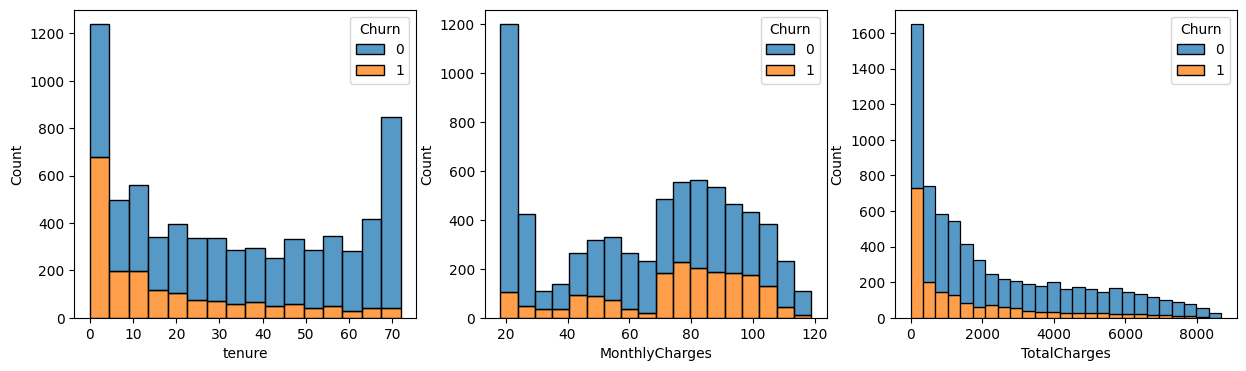

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, col in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
  sns.histplot(df, x=col, hue='Churn', multiple='stack', ax=ax)
plt.show()

In [13]:
df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].corr()

,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.000000,0.247900,0.826178,-0.352229
MonthlyCharges,0.247900,1.000000,0.651174,0.193356
TotalCharges,0.826178,0.651174,1.000000,-0.198324
Churn,-0.352229,0.193356,-0.198324,1.000000


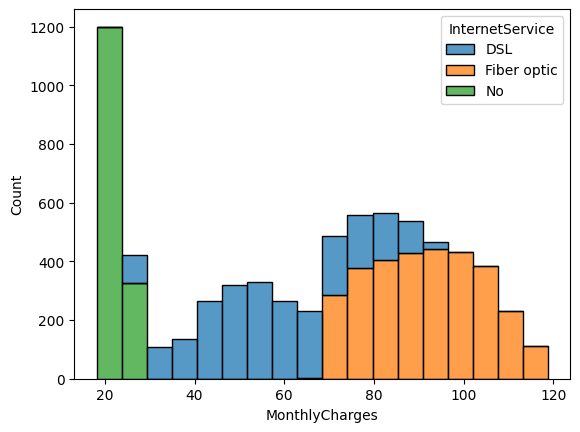

In [14]:
sns.histplot(data=df, x="MonthlyCharges", hue="InternetService", multiple="stack")
plt.show()

In [15]:
pd.crosstab(df["InternetService"], df["Contract"], normalize="index")

Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,0.505163,0.235440,0.259397
Fiber optic,0.687339,0.174096,0.138566
No,0.343381,0.238532,0.418087


In [16]:
X = pd.get_dummies(df.drop(columns='Churn'), drop_first='True')
y = df['Churn']

X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

baseline = sklearn.dummy.DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

print(sklearn.metrics.classification_report(y_test, baseline.predict(X_test), zero_division=0))

              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1552
           1       0.00      0.00      0.00       561

    accuracy                           0.73      2113
   macro avg       0.37      0.50      0.42      2113
weighted avg       0.54      0.73      0.62      2113



In [17]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate


X_train = X_train.astype(float)
X_test = X_test.astype(float)

models = {
    'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=1),
    'NaiveBayes': make_pipeline(StandardScaler(), GaussianNB()),
    'SVM': make_pipeline(StandardScaler(), SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42))
}

models['Voting (Soft)'] = VotingClassifier(estimators = [(n, m) for n, m in models.items()], voting='soft', n_jobs=-1)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
rows = {}

for name, model in models.items():
  res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
  rows[name] = {m: res[f"test_{m}"].mean() for m in scoring}

pd.DataFrame(rows).T.round(3).sort_values('roc_auc', ascending=False)


,accuracy,precision,recall,f1,roc_auc
Voting (Soft),0.749,0.519,0.779,0.623,0.836
RandomForest,0.791,0.647,0.473,0.546,0.828
SVM,0.741,0.509,0.781,0.616,0.824
NaiveBayes,0.664,0.434,0.878,0.581,0.822


In [19]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score
import numpy as np

voting = models["Voting (Soft)"]

# Out-of-fold probabilities on the training set
oof = cross_val_predict(voting, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_thr = thr[np.argmax(f1s)]
print("Best threshold for F1:", round(best_thr, 3))

# Final fit, single look at the test set
voting.fit(X_train, y_train)
proba = voting.predict_proba(X_test)[:, 1]
print("Test ROC-AUC:", roc_auc_score(y_test, proba))

print("--- threshold 0.5 ---")
print(classification_report(y_test, (proba >= 0.5).astype(int)))
print(f"--- threshold {best_thr:.2f} ---")
print(classification_report(y_test, (proba >= best_thr).astype(int)))

Best threshold for F1: 0.557
Test ROC-AUC: 0.82925659720308
--- threshold 0.5 ---
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1552
           1       0.51      0.77      0.62       561

    accuracy                           0.75      2113
   macro avg       0.71      0.75      0.71      2113
weighted avg       0.80      0.75      0.76      2113

--- threshold 0.56 ---
              precision    recall  f1-score   support

           0       0.88      0.78      0.83      1552
           1       0.54      0.72      0.62       561

    accuracy                           0.77      2113
   macro avg       0.71      0.75      0.73      2113
weighted avg       0.79      0.77      0.77      2113

